In [1]:
import sys, os, warnings, subprocess
subprocess.run(["pip", "install", ".", "--quiet"], check=True,
               cwd="/mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales")
warnings.simplefilter("ignore", UserWarning)

import numpy as np
import scipy as sp
import pandas as pd
import pygam

import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

%matplotlib inline
plt.rcParams.update({
    'font.size':         8,
    'figure.dpi':        300,
    'svg.fonttype':      'none',
    'font.family':       'sans-serif',
    'font.sans-serif':   ['Roboto'],
    'axes.spines.top':   False,
    'axes.spines.right': False,
})

sys.path.extend([r'/mnt/storage_ssd_raid/research_projects/snaplab_tools'])

from src.notebook import load_notebook_data
from src.timescales import (create_ints_dataframe_custom_grouping, convert_data_dict,
                             average_data_dict_converted, compute_deflections)
from src.plotting import create_sydnor_sa_colormap
from src.gams import (fit_all_panels, apply_region_mask,
                      get_series_colors, get_draw_order, add_colorbar, style_ax,
                      compute_partial_r2_age)

  DEPRECATION: Building 'src' using the legacy setup.py bdist_wheel mechanism, which will be removed in a future version. pip 25.3 will enforce this behaviour change. A possible replacement is to use the standardized build interface by setting the `--use-pep517` option, (possibly combined with `--no-build-isolation`), or adding a `pyproject.toml` file to the source tree of 'src'. Discussion can be found at https://github.com/pypa/pip/issues/6334


In [2]:
from sklearn.linear_model import LinearRegression

def residualize(y, covariates):
    """Regress covariates out of y; return residuals (NaN preserved)."""
    mask  = ~np.isnan(y)
    resid = np.full(len(y), np.nan)
    if mask.sum() < 10:
        return resid
    lr = LinearRegression().fit(covariates[mask], y[mask])
    resid[mask] = y[mask] - lr.predict(covariates[mask])
    return resid

# Load data

In [3]:
dataset       = 'HCP-D'
which_modality = 'FMRI'
# output_type   = 'timescale_auc_zero_crossing'
output_type   = 'timescale_auc_zero_crossing_bp-0.01-0.08hz'
# output_type   = 'timescale_auc_zero_crossing_bp-0.08-0.15hz'

notebook_data = load_notebook_data(dataset=dataset, which_modality=which_modality,
                                   output_type=output_type, use_resids=True)

Loading data for notebooks...
Initialized DataLoader for dataset: HCP-D
  Base directory:        /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D
  Raw data directory:    /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D/processed
  Derivatives directory: /mnt/lindenmp_bignas/lindenmp/research_data/HCP_D/derivatives
  Output directory:      /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
  Behavioral data:       565 subjects

	Initialized Timescales for dataset: HCP-D
	Output directory: /mnt/storage_ssd_raid/research_projects/intrinsic_neural_timescales
Loaded 2760 scans from scan_registry_HCP-D.csv


Loading metric_tsnr: 100%|██████████| 2760/2760 [00:00<00:00, 7577.05it/s]


2760
timescale_auc_zero_crossing_bp-0.01-0.08hz


Loading timescale_auc_zero_crossing_bp-0.01-0.08hz: 100%|██████████| 2760/2760 [00:00<00:00, 8472.09it/s]


2760


Loading timescale_auc_zero_crossing_bp-0.01-0.08hz_resids: 100%|██████████| 2760/2760 [00:00<00:00, 8276.70it/s]

2760
Number of subjects: 552


In [4]:
timescales_processor = notebook_data['timescales_processor']
data_dict            = notebook_data['data_dict']
results_dir          = notebook_data['results_dir']

if dataset == 'HCP-D':
    parcellation  = 'schaefer_400-7'
    sa_axis_file  = os.path.join(timescales_processor.output_dir, 'data', 'supporting_data',
                                 'schaefer400-7_sa-axis.npy')
elif dataset in ('PNC', 'NKI', 'HBN'):
    parcellation  = 'schaefer_400-17'
    sa_axis_file  = os.path.join(timescales_processor.output_dir, 'data', 'supporting_data',
                                 'schaefer400-17_sa-axis.npy')
sa_axis = sp.stats.rankdata(np.load(sa_axis_file))

nas_scratch_dir = f'/mnt/lindenmp_nas/lindenmp/work/figure_scratch/intrinsic_neural_timescales/{dataset}'
os.makedirs(nas_scratch_dir, exist_ok=True)

# Prepare data

In [5]:
timescales_processor.match_registry_to_behavior()
df_behavior = timescales_processor.df_behavior_matched.copy()
subject_ids = list(dict.fromkeys(scan.subject_id for scan in timescales_processor.scan_registry))
n_subs      = len(subject_ids)
print(f'Number of subjects: {n_subs}')

if dataset == 'HCP-D':
    rest_scan = 'task-Rest'
    task_scan = 'tfMRICARITPA'
elif dataset == 'PNC':
    rest_scan = 'rest'
    task_scan = 'frac2back'
elif dataset == 'HBN':
    rest_scan = 'rest'
    task_scan = None

data_dict_tsnr      = notebook_data['data_dict_tsnr']
data_dict_converted = convert_data_dict(data_dict, timescales_processor.scan_registry)
data_dict_centiles  = convert_data_dict(data_dict, timescales_processor.scan_registry,
                                        brain_map=sa_axis)
data_dict_converted = average_data_dict_converted(data_dict_converted, average_all_rest=True)
data_dict_centiles  = average_data_dict_converted(data_dict_centiles,  average_all_rest=True)
df_tsnr             = create_ints_dataframe_custom_grouping(data_dict_tsnr, average_all_rest=True)

Number of subjects: 552
rfMRIREST1PA (552, 400)
rfMRIREST2PA (552, 400)
tfMRICARITPA (552, 400)
tfMRIEMOTIONPA (552, 400)
tfMRIGUESSINGPA (552, 400)
rfMRIREST1PA (552, 10)
rfMRIREST2PA (552, 10)
tfMRICARITPA (552, 10)
tfMRIEMOTIONPA (552, 10)
tfMRIGUESSINGPA (552, 10)


# Fit GAMs

In [6]:
age      = df_behavior['age'].values
nuisance = df_behavior[['sex', 'meanFD']].values if dataset == 'HCP-D' else None
age_grid = np.linspace(age.min(), age.max(), 200)

# Region-level data (used for regional fits and deflection computation)
rest_full = data_dict_converted[rest_scan]
try:
    task_full = data_dict_converted[task_scan]
except (KeyError, TypeError):
    task_full = data_dict_converted[rest_scan]
n_regions  = task_full.shape[1]

# deflection_full = np.zeros(task_full.shape)
# for i in range(n_subs):
#     deflection_full[i, :] = compute_deflections(rest_full[i, :], task_full[i, :],
#                                                 nuisance_regression=True,
#                                                 standardize=False, absolute=True)
deflection_full = compute_deflections(rest_full, task_full,
                                      nuisance_regression=False,
                                      standardize=False, absolute=True)

# --- Decile-binned data (panels 1 & 2) ---
rest_dec = data_dict_centiles[rest_scan]
try:
    task_dec = data_dict_centiles[task_scan]
except (KeyError, TypeError):
    task_dec = data_dict_centiles[rest_scan]

# deflection_dec = np.zeros(task_dec.shape)
# for i in range(n_subs):
#     deflection_dec[i, :] = compute_deflections(rest_dec[i, :], task_dec[i, :],
#                                                nuisance_regression=True,
#                                                standardize=False, absolute=True)
deflection_dec = compute_deflections(rest_dec, task_dec,
                                     nuisance_regression=False,
                                     standardize=False, absolute=True)

n_deciles     = rest_dec.shape[1]
results_dec   = fit_all_panels(age, rest_dec, task_dec, deflection_dec, age_grid,
                               n_splines=4, lam=0.1, demean=True, show_ci=False,
                               nuisance=nuisance)

cmap          = create_sydnor_sa_colormap()
series_colors = get_series_colors('decile', n_deciles, cmap)
draw_order    = get_draw_order('decile', n_deciles)

# --- Region-level fits (panel 3) ---
apply_tsnr_mask = False  # set False to use all regions

if apply_tsnr_mask:
    region_mask = (df_tsnr[task_scan] < np.quantile(df_tsnr[task_scan], q=0.1)).values
else:
    region_mask = None

rest_reg, task_reg, defl_reg, sa_axis_reg = apply_region_mask(
    region_mask, rest_full, task_full, deflection_full, sa_axis=sa_axis)

results_reg = fit_all_panels(age, rest_reg, task_reg, defl_reg, age_grid,
                             n_splines=4, lam=0.1, demean=True, show_ci=False,
                             nuisance=nuisance)
print(f'Decile shape: {deflection_dec.shape}  |  Regional shape: {defl_reg.shape}')

Decile shape: (552, 10)  |  Regional shape: (552, 400)


In [7]:
# Partial R² of age smooth on INT deflections (per region, after controlling for sex + meanFD)
partial_r2_defl = compute_partial_r2_age(defl_reg, age,
                                          results_reg['deflection']['gams'],
                                          nuisance=nuisance, demean=True)

# Per-region Pearson r and Spearman rho: age vs INT deflections
from scipy.stats import pearsonr, spearmanr
pearson_r  = np.full(n_regions, np.nan)
spearman_r = np.full(n_regions, np.nan)
for i in range(n_regions):
    y = defl_reg[:, i]
    ok = ~np.isnan(y)
    if ok.sum() > 2:
        pearson_r[i]  = pearsonr(age[ok],  y[ok]).statistic
        spearman_r[i] = spearmanr(age[ok], y[ok]).statistic

# Reconstruct full parcellation-length vectors (NaN for tSNR-excluded regions if mask applied)
if region_mask is not None:
    valid_mask = ~np.asarray(region_mask, dtype=bool)
    partial_r2_full = np.full(sa_axis.shape[0], np.nan)
    partial_r2_full[valid_mask] = partial_r2_defl
    pearson_r_full  = np.full(sa_axis.shape[0], np.nan)
    pearson_r_full[valid_mask]  = pearson_r
    spearman_r_full = np.full(sa_axis.shape[0], np.nan)
    spearman_r_full[valid_mask] = spearman_r
else:
    partial_r2_full = partial_r2_defl.copy()
    pearson_r_full  = pearson_r.copy()
    spearman_r_full = spearman_r.copy()

print(f'Partial R²  range: [{np.nanmin(partial_r2_full):.4f}, {np.nanmax(partial_r2_full):.4f}]')
print(f'Pearson r   range: [{np.nanmin(pearson_r_full):.4f},  {np.nanmax(pearson_r_full):.4f}]')
print(f'Spearman ρ  range: [{np.nanmin(spearman_r_full):.4f},  {np.nanmax(spearman_r_full):.4f}]')

Partial R²  range: [-0.0001, 0.0264]
Pearson r   range: [-0.1585,  0.0992]
Spearman ρ  range: [-0.1645,  0.0952]


In [8]:
from matplotlib.gridspec import GridSpec

def compute_deriv_sa_corr(deriv, sa_axis_vals, method='pearson'):
    """Pearson/Spearman r between per-region SA values and derivative at each age point."""
    n_grid  = deriv.shape[1]
    rhos    = np.full(n_grid, np.nan)
    corr_fn = sp.stats.pearsonr if method == 'pearson' else sp.stats.spearmanr
    for t in range(n_grid):
        col  = deriv[:, t]
        mask = ~np.isnan(col)
        if mask.sum() > 2:
            rhos[t] = corr_fn(sa_axis_vals[mask], col[mask]).statistic
    return rhos

# Figure 4

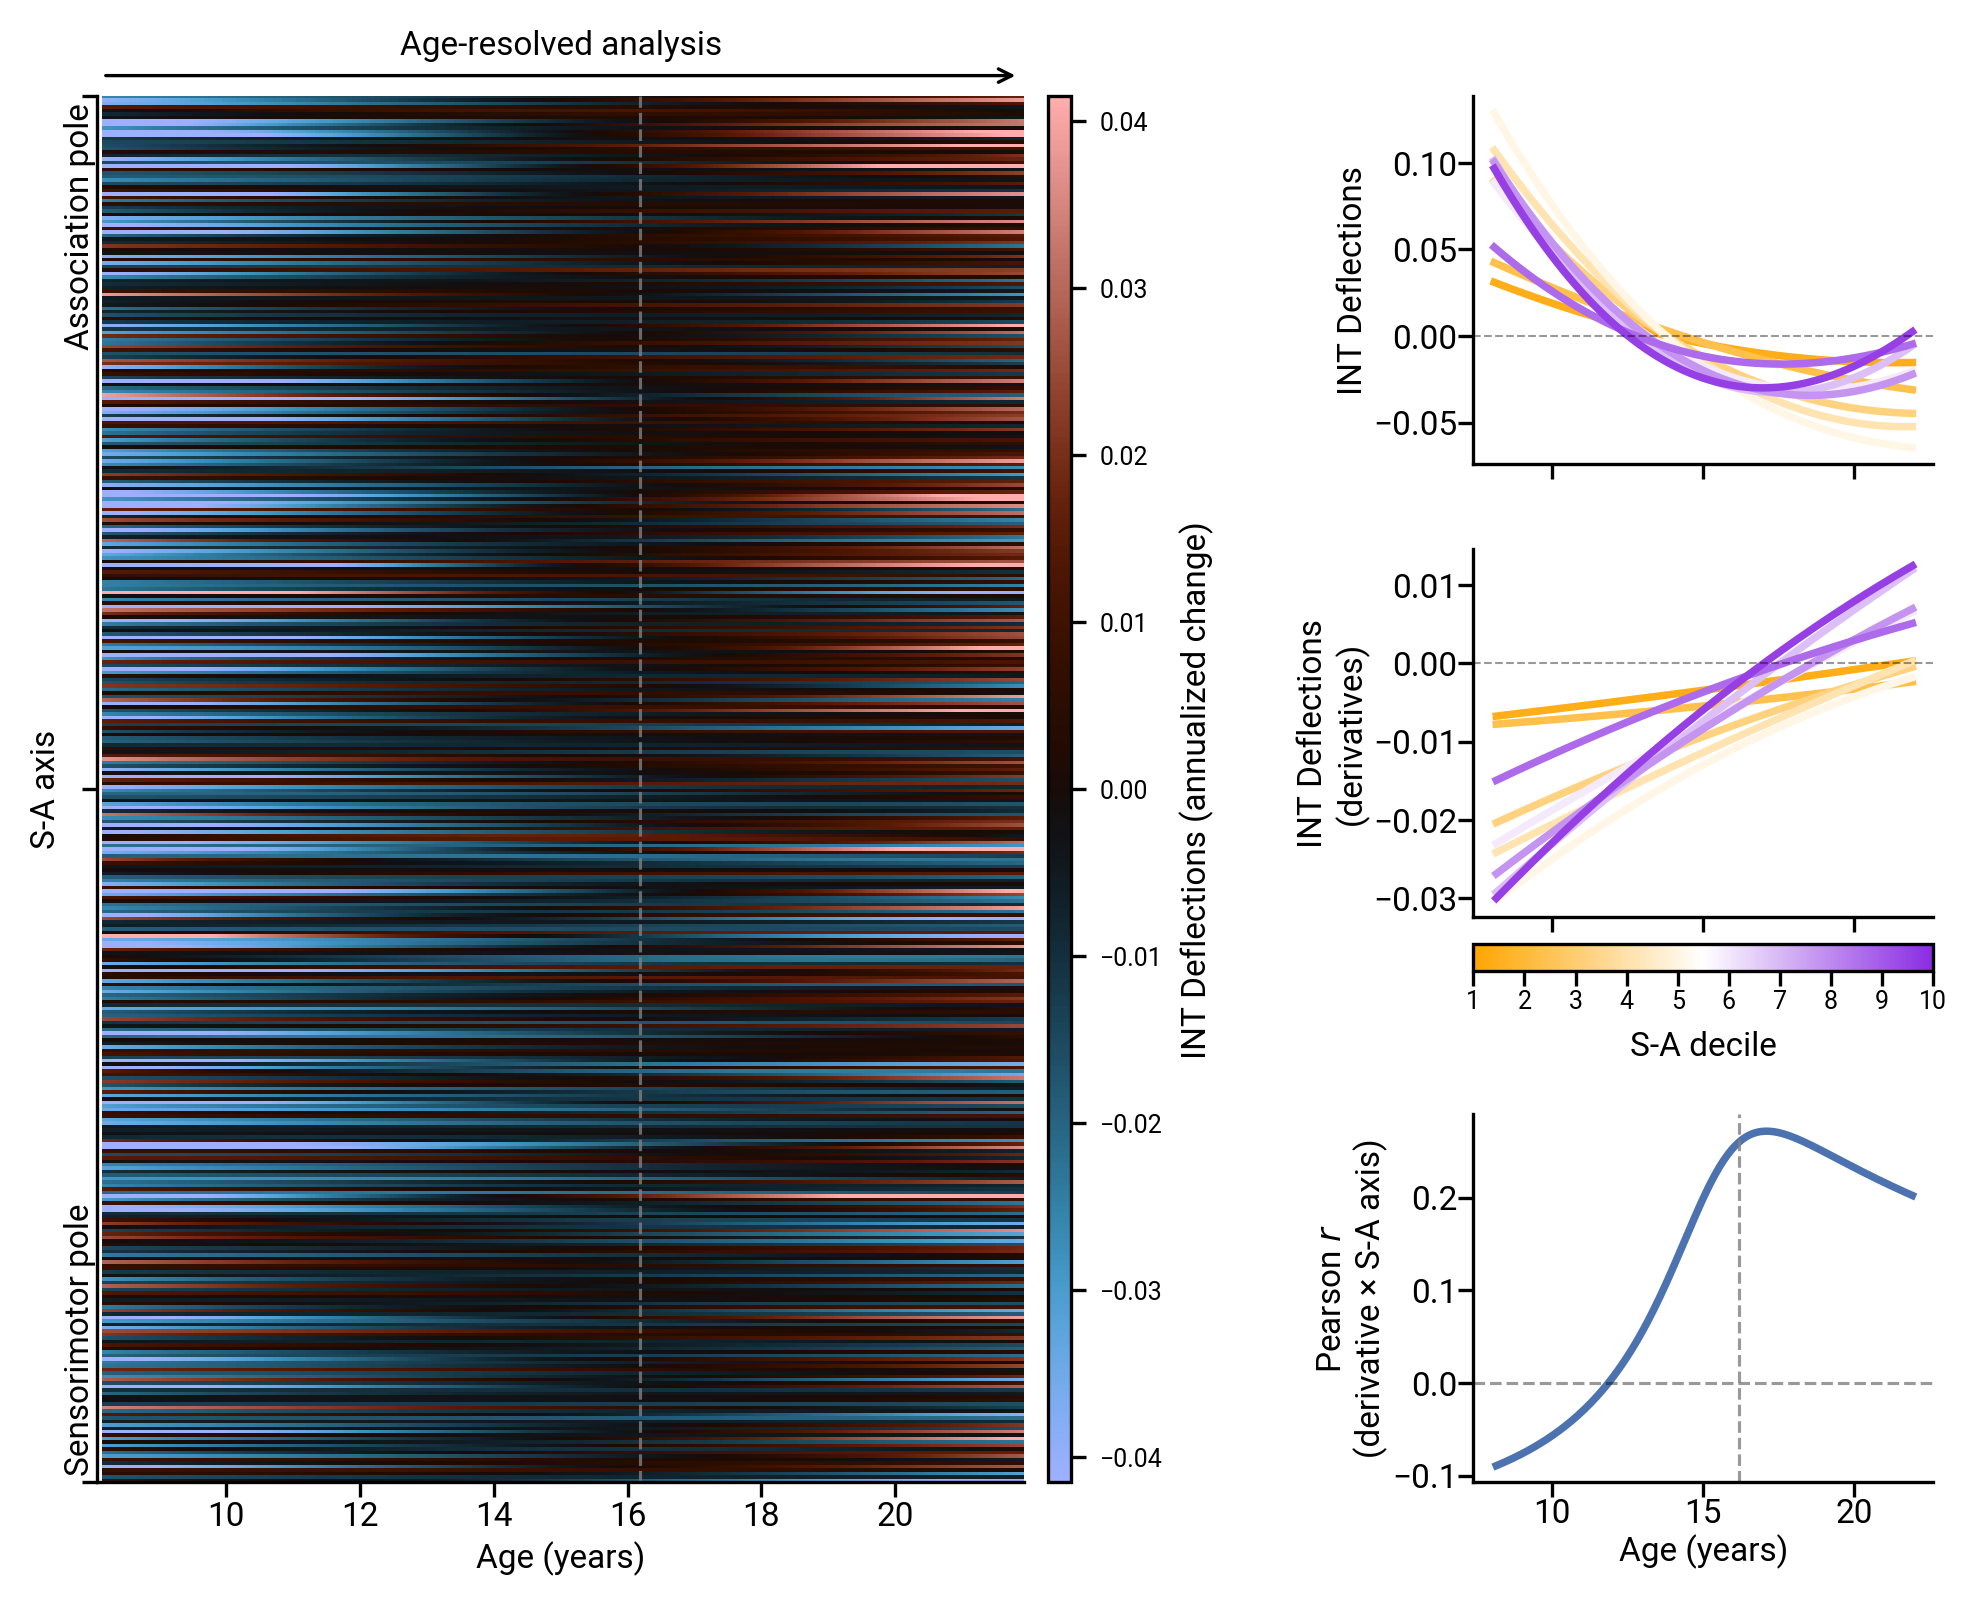

In [9]:
# --- Parameters ---
signal_type = 'deflection'  # 'rest', 'task', or 'deflection'
plot_level  = 'region'      # 'region' or 'decile'
# ------------------

_signal_labels = {'rest': 'REST INTs', 'task': 'Task INTs', 'deflection': 'INT Deflections'}
lw = 1.8

# ── Heatmap data ──────────────────────────────────────────────────────────────
if plot_level == 'region':
    _deriv_raw   = {'rest': results_reg['rest']['deriv'],
                    'task': results_reg['task']['deriv'],
                    'deflection': results_reg['deflection']['deriv']}[signal_type]
    sort_idx     = np.argsort(sa_axis_reg)
    deriv_sorted = _deriv_raw[sort_idx]
    ylabel       = 'S-A axis'
    bottom_label = 'Sensorimotor pole'
    top_label    = 'Association pole'
else:
    deriv_sorted = {'rest': results_dec['rest']['deriv'],
                    'task': results_dec['task']['deriv'],
                    'deflection': results_dec['deflection']['deriv']}[signal_type]
    ylabel       = 'S-A axis decile'
    bottom_label = 'Sensorimotor'
    top_label    = 'Association'

n_rows = deriv_sorted.shape[0]
vmax   = np.nanpercentile(np.abs(deriv_sorted), 98)

crossing_ages = []
for i in range(n_rows):
    row = deriv_sorted[i, :]
    for t in range(len(row) - 1):
        if row[t] < 0 and row[t + 1] >= 0:
            frac = -row[t] / (row[t + 1] - row[t])
            crossing_ages.append(age_grid[t] + frac * (age_grid[t + 1] - age_grid[t]))
            break
mean_cross_age = np.mean(crossing_ages) if crossing_ages else None

# ── Pearson r ─────────────────────────────────────────────────────────────────
rhos = compute_deriv_sa_corr(
    {'rest': results_reg['rest']['deriv'],
     'task': results_reg['task']['deriv'],
     'deflection': results_reg['deflection']['deriv']}[signal_type],
    sa_axis_reg, method='pearson')

# ── Figure layout ─────────────────────────────────────────────────────────────
from matplotlib.gridspec import GridSpecFromSubplotSpec

fig      = plt.figure(figsize=(9, 6), dpi=300)
gs_outer = GridSpec(1, 2, figure=fig, width_ratios=[1, 1], wspace=0.15)

# Left column: heatmap | narrow vertical colorbar
gs_left   = GridSpecFromSubplotSpec(1, 2, subplot_spec=gs_outer[0],
                                    width_ratios=[1, 0.025], wspace=0.05)
ax_heat   = fig.add_subplot(gs_left[0])
ax_cbar_h = fig.add_subplot(gs_left[1])

# Right column: pred / deriv / SA-decile cbar / Pearson r
gs_right   = GridSpecFromSubplotSpec(4, 1, subplot_spec=gs_outer[1],
                                     height_ratios=[1, 1, 0.075, 1], hspace=0.3)
ax0        = fig.add_subplot(gs_right[0])
ax1        = fig.add_subplot(gs_right[1], sharex=ax0)
ax_cbar_sa = fig.add_subplot(gs_right[2])
ax2        = fig.add_subplot(gs_right[3], sharex=ax0)

# Tuck SA decile colorbar just below ax1


# ── Heatmap ───────────────────────────────────────────────────────────────────
im = ax_heat.imshow(
    deriv_sorted, aspect='auto', origin='lower',
    extent=[age_grid[0], age_grid[-1], 0, n_rows],
    cmap='berlin', vmin=-vmax, vmax=vmax, interpolation='nearest',
)
if mean_cross_age is not None:
    ax_heat.axvline(mean_cross_age, color='gray', linestyle='--', lw=0.75, alpha=0.8)

ax_heat.set_xlabel('Age (years)', fontsize=8, labelpad=2)
ax_heat.set_ylabel(ylabel, fontsize=8, labelpad=4)
if plot_level == 'region':
    ax_heat.set_yticks([0, n_rows // 2, n_rows])
    ax_heat.set_yticklabels(['', '', ''], fontsize=8)
else:
    ax_heat.set_yticks(np.arange(n_rows) + 0.5)
    ax_heat.set_yticklabels([str(i + 1) for i in range(n_rows)], fontsize=8)
ax_heat.tick_params(labelsize=8, pad=1)

ax_heat.annotate(top_label,    xy=(age_grid[0], n_rows), xytext=(-8, -1.5), rotation=90,
                 textcoords='offset points', fontsize=8, va='top',    annotation_clip=False)
ax_heat.annotate(bottom_label, xy=(age_grid[0], 0),      xytext=(-8,  1.5), rotation=90,
                 textcoords='offset points', fontsize=8, va='bottom', annotation_clip=False)
ax_heat.annotate('', xy=(age_grid[-1], n_rows + n_rows * 0.015),
                 xytext=(age_grid[0],  n_rows + n_rows * 0.015),
                 arrowprops=dict(arrowstyle='->', color='k', lw=0.8), annotation_clip=False)
ax_heat.text((age_grid[0] + age_grid[-1]) / 2, n_rows + n_rows * 0.025,
             'Age-resolved analysis', ha='center', va='bottom', fontsize=8, clip_on=False)

cb_h = fig.colorbar(im, cax=ax_cbar_h, orientation='vertical')
cb_h.set_label(f'{_signal_labels[signal_type]} (annualized change)', fontsize=8)
cb_h.ax.yaxis.set_label_position('right')
cb_h.ax.tick_params(labelsize=6)

# ── Line plots ────────────────────────────────────────────────────────────────
for i in draw_order:
    ax0.plot(age_grid, results_dec[signal_type]['pred'][i], color=series_colors[i], lw=lw)
style_ax(ax0, 'Age (years)', f'{_signal_labels[signal_type]}', None, demean=True)
ax0.set_xlabel('')
ax0.set_box_aspect(0.8)
plt.setp(ax0.get_xticklabels(), visible=False)

for i in draw_order:
    ax1.plot(age_grid, results_dec[signal_type]['deriv'][i], color=series_colors[i], lw=lw)
style_ax(ax1, 'Age (years)', f'{_signal_labels[signal_type]}\n(derivatives)', None, demean=True)
ax1.set_xlabel('')
ax1.set_box_aspect(0.8)
plt.setp(ax1.get_xticklabels(), visible=False)

# Reposition SA decile colorbar to match ax1 actual rendered width (after box_aspect)
fig.canvas.draw()
renderer    = fig.canvas.get_renderer()
bbox1       = ax1.get_window_extent(renderer=renderer)
fig_w_px, fig_h_px = fig.get_size_inches() * fig.dpi
x0_f   = bbox1.x0 / fig_w_px
y0_f   = bbox1.y0 / fig_h_px
w_f    = bbox1.width / fig_w_px
cbar_height = 0.015
pad         = 0.015
ax_cbar_sa.set_position([x0_f, y0_f - pad - cbar_height, w_f, cbar_height])

norm_sa = mcolors.Normalize(vmin=1, vmax=n_deciles)
sm_sa   = plt.cm.ScalarMappable(cmap=cmap, norm=norm_sa)
sm_sa.set_array([])
cb_sa = fig.colorbar(sm_sa, cax=ax_cbar_sa, orientation='horizontal')
cb_sa.set_label('S-A decile', fontsize=8)
cb_sa.set_ticks(list(range(1, n_deciles + 1)))
cb_sa.ax.tick_params(labelsize=6, pad=1)

ax2.plot(age_grid, rhos, color='#4C72B0', lw=lw)
ax2.axhline(0, color='k', lw=0.75, ls='--', alpha=0.4)
ax2.set_xlabel('Age (years)', fontsize=8, labelpad=1)
ax2.set_ylabel(f'Pearson $r$\n(derivative × S-A axis)', fontsize=8, labelpad=1)
ax2.tick_params(labelsize=8, pad=0.25)
ax2.set_box_aspect(0.8)
ax2.spines[['top', 'right']].set_visible(False)
if mean_cross_age is not None:
    ax2.axvline(mean_cross_age, color='gray', linestyle='--', lw=0.75, alpha=0.8)

fig.savefig(os.path.join(nas_scratch_dir, 'fig4_combined.png'),
            dpi=1000, bbox_inches='tight', transparent=True)
plt.show()

In [10]:
# # ── Brain surface figure ──────────────────────────────────────────────────────
# # brain_metric options: 'partial_r2', 'pearson_r', 'spearman_r'
# brain_metric = 'pearson_r'

# _metric_cfg = {
#     'partial_r2': (partial_r2_full, 'magma',  False,
#                    0,    np.nanpercentile(partial_r2_full, 98),
#                    'Partial $R^2$ (age ~ INT deflection)'),
#     'pearson_r':  (pearson_r_full,  'RdBu_r', True,
#                    None, None,
#                    'Pearson $r$ (age ~ INT deflection)'),
#     'spearman_r': (spearman_r_full, 'RdBu_r', True,
#                    None, None,
#                    'Spearman $\\rho$ (age ~ INT deflection)'),
# }
# data_vec, cmap_br, sym_cbar, vmin_fixed, vmax_fixed, cbar_lbl = _metric_cfg[brain_metric]

# if sym_cbar:
#     _abs_max = np.nanpercentile(np.abs(data_vec), 98)
#     vmin_br, vmax_br = -_abs_max, _abs_max
# else:
#     vmin_br, vmax_br = vmin_fixed, vmax_fixed

# # ── Layout ────────────────────────────────────────────────────────────────────
# cbar_frac = 0.13
# px        = 0.005
# quarter_w = 0.25
# aw        = quarter_w - 2 * px
# ah        = 1.0 - cbar_frac

# fig_brain = plt.figure(figsize=(9, 3), dpi=300)

# ax_positions = [
#     [0 * quarter_w + px, cbar_frac, aw, ah],
#     [1 * quarter_w + px, cbar_frac, aw, ah],
#     [2 * quarter_w + px, cbar_frac, aw, ah],
#     [3 * quarter_w + px, cbar_frac, aw, ah],
# ]
# brain_axes = [fig_brain.add_axes(pos, projection='3d') for pos in ax_positions]

# surf_data_left, surf_data_right, surf_mesh, _, _ = _prepare_brain_surface_data(
#     data_vec, parcellation, 'fsaverage5', None,
#     vmin_br, vmax_br, None, False)

# _render_brain_surface_views(fig_brain, brain_axes, surf_data_left, surf_data_right,
#                              surf_mesh, vmin_br, vmax_br, cmap_br, None, 0.8, 0.7, 6,
#                              inflated=True)

# for ax in brain_axes:
#     try:
#         ax.dist = 5.5
#     except AttributeError:
#         pass

# cax_br  = fig_brain.add_axes([0.2, 0.25, 0.6, 0.05])
# norm_br = mcolors.Normalize(vmin=vmin_br, vmax=vmax_br)
# sm_br   = plt.cm.ScalarMappable(norm=norm_br, cmap=cmap_br)
# sm_br.set_array([])
# cbar_br = fig_brain.colorbar(sm_br, cax=cax_br, orientation='horizontal')
# cbar_br.set_label(cbar_lbl, fontsize=6)
# cbar_br.ax.tick_params(labelsize=6)

# fig_brain.savefig(os.path.join(nas_scratch_dir, 'fig4_brain_surface.png'),
#                   dpi=1000, bbox_inches='tight', transparent=True)
# plt.show()